## Variables de sol du projet African Crop Yield Intelligence

Ce notebook contrôle les couches de SoilGrids 2.0 acquises pour le projet et les variables de sol construites pour chaque lieu de `regional` et de `survey`. Il fait suite à `06_climate_variables.ipynb` et relève des phases Data Understanding et Data Preparation de CRISP-DM pour les sources externes.

**Décisions de départ**

- Les sols proviennent de SoilGrids 2.0 dans sa version agrégée à 1 km, décision arrêtée le 3 novembre 2026 et rappelée à la section 7 de `docs/explanatory_variables.md`.
- Neuf propriétés sont retenues, à savoir les parts d'argile, de limon et de sable, le carbone organique, l'azote total, le pH dans l'eau, la capacité d'échange cationique, la densité apparente et la part volumique d'éléments grossiers.
- Chaque propriété est moyennée de 0 à 30 cm, profondeur qui concentre l'essentiel des racines des cultures annuelles. Les couches de 0 à 5 cm, de 5 à 15 cm et de 15 à 30 cm sont pondérées par leur épaisseur.
- Les lieux sont ceux des variables climatiques. Un lieu de `regional` est sa zone, et un lieu de `survey` est le voisinage de 5 km de sa grappe, ou sa zone de repli lorsque les coordonnées manquent.

**Préalable**

Les couches sont obtenues par `python -m src.features.sols extraire`, puis les variables sont construites par `python -m src.features.sols construire`, qui écrit `sols_regional.csv.gz` et `sols_survey.csv.gz` dans `data/processed`. Les sections 3 et 4 lisent à distance quelques fenêtres de la version à 250 m, et le notebook s'exécute en six minutes environ.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

from src.data.load import DOSSIER_TRAITE
from src.features.acquisition import REGISTRE
from src.features.controles_sols import (
    comparer_apercu,
    decalage_agregat,
    ecart_echelle,
    fenetre_autour,
    fermeture_texture,
    resumer_couches,
)
from src.features.sols import DOSSIER_SOILGRIDS, PROFONDEURS, PROPRIETES, couche_0_30

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
SITES = {"Malawi central": (34.0, -13.5), "Niger occidental": (2.5, 13.5), "Hauts plateaux éthiopiens": (38.5, 9.0)}

### 1. Tests unitaires

La suite complète couvre la préparation, le protocole d'évaluation, la géographie, le climat et les sols. Les tests propres aux sols vérifient le découpage, le refus d'une grille inattendue, la moyenne pondérée par l'épaisseur, l'attribution des pixels à un lieu et la moyenne des pixels valides.

In [2]:
execution = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-t", "."],
    cwd=RACINE, capture_output=True, text=True,
)
print(execution.stderr.strip().splitlines()[-3:])

['Ran 81 tests in 1.350s', '', 'OK']


### 2. Intégrité des sources

SoilGrids publie l'empreinte SHA-256 de chacun de ses fichiers. Cette empreinte ne peut être vérifiée que sur un fichier complet. Chaque fichier source a donc été téléchargé en entier, comparé à son empreinte publiée, découpé sur une fenêtre fixe couvrant tous les lieux du projet, puis supprimé. Le pH manque dans la version à 1 km. Il est lu dans le premier aperçu de sa mosaïque à 250 m, fichier `.vrt.ovr` publié avec son empreinte, dont la section 3 établit l'équivalence avec la version à 1 km.

In [3]:
sources = pd.read_csv(DOSSIER_SOILGRIDS / "sources.csv")
registre = pd.read_csv(REGISTRE)
decoupes = registre[registre["fichier"].str.startswith("soilgrids/")]
attendues = {f"{p}_{d}_mean_1000_afrique.tif" for p in PROPRIETES for d in PROFONDEURS}
print("Couches attendues :", len(attendues), "| sources vérifiées :", sources["fichier"].nunique(),
      "| découpages consignés :", decoupes["fichier"].nunique(),
      "| manquantes :", sorted(attendues - set(sources["fichier"])))
print("Volume des sources vérifiées :", round(sources["octets_source"].sum() / 1e9, 2), "Go",
      "| volume des découpages conservés :", round(decoupes["octets"].sum() / 1e6), "Mo")
print("Dates de dernière modification des sources :", sorted(pd.to_datetime(sources["derniere_modification"], format="%a, %d %b %Y %H:%M:%S GMT").dt.date.unique()))
display(sources[["fichier", "octets_source", "derniere_modification"]].sort_values("fichier").reset_index(drop=True))

Couches attendues : 27 | sources vérifiées : 27 | découpages consignés : 27 | manquantes : []
Volume des sources vérifiées : 4.68 Go | volume des découpages conservés : 787 Mo
Dates de dernière modification des sources : [datetime.date(2020, 4, 9), datetime.date(2022, 6, 2)]


,fichier,octets_source,derniere_modification
0,bdod_0-5cm_mean_1000_afrique.tif,114696796,"Thu, 02 Jun 2022 16:01:45 GMT"
1,bdod_15-30cm_mean_1000_afrique.tif,108464241,"Thu, 02 Jun 2022 16:01:46 GMT"
2,bdod_5-15cm_mean_1000_afrique.tif,110211361,"Thu, 02 Jun 2022 16:01:51 GMT"
3,cec_0-5cm_mean_1000_afrique.tif,183213341,"Thu, 02 Jun 2022 16:02:55 GMT"
4,cec_15-30cm_mean_1000_afrique.tif,182791202,"Thu, 02 Jun 2022 16:02:58 GMT"
5,cec_5-15cm_mean_1000_afrique.tif,182914931,"Thu, 02 Jun 2022 16:03:04 GMT"
6,cfvo_0-5cm_mean_1000_afrique.tif,191478281,"Thu, 02 Jun 2022 16:03:39 GMT"
7,cfvo_15-30cm_mean_1000_afrique.tif,195978151,"Thu, 02 Jun 2022 16:03:45 GMT"
8,cfvo_5-15cm_mean_1000_afrique.tif,193416902,"Thu, 02 Jun 2022 16:03:50 GMT"
9,clay_0-5cm_mean_1000_afrique.tif,191530251,"Thu, 02 Jun 2022 16:02:45 GMT"


**Constat**

- Les 27 couches attendues, soit neuf propriétés à trois profondeurs, ont été obtenues. Les 27 fichiers sources, qui totalisent 4,68 Go, ont tous la même empreinte que celle publiée par ISRIC.
- Seuls les découpages sont conservés, soit 787 Mo dans `data/external/soilgrids`. Chacun est consigné dans le registre des données externes, et l'empreinte vérifiée de sa source dans `sources.csv`.
- Les fichiers à 1 km datent du 2 juin 2022 et les aperçus du pH du 9 avril 2020.

**Analyse**

La vérification porte sur les fichiers complets, et non sur une lecture partielle. Le téléchargement complet, plus long qu'une lecture à distance par fenêtres, a été préféré pour cette raison. Il a duré une heure environ, le serveur limitant le débit de chaque connexion à 0,4 Mo par seconde.

**Conséquences pour la suite**

Les découpages sont reproductibles à l'identique tant qu'ISRIC ne remplace pas ses fichiers. Une nouvelle version serait détectée par une empreinte différente, et le téléchargement s'arrêterait.

### 3. Nature de la version à 1 km

La documentation de SoilGrids indique que la version à 1 km est une agrégation de la version à 250 m, sans en préciser la méthode. Deux contrôles la caractérisent sur des fenêtres lues à distance. Le premier compare chaque découpage au premier aperçu de la mosaïque à 250 m de la même propriété. Le second compare chaque pixel à 1 km à la moyenne des 16 pixels à 250 m de même étendue, puis à celle de blocs décalés de quelques pixels fins vers l'est par dx ou vers le sud par dy. Les écarts du second tableau sont exprimés dans les unités de stockage de SoilGrids, soit le g/kg pour l'argile, le dg/kg pour le carbone organique et le cg/cm³ pour la densité apparente.

In [4]:
fenetre = fenetre_autour(*SITES["Malawi central"], 256)
coherence = pd.DataFrame(
    [(PROPRIETES[p][0], *comparer_apercu(p, "0-5cm", fenetre)) for p in PROPRIETES],
    columns=["propriete", "origine de la mosaique a 250 m", "part de pixels identiques"],
)
display(coherence)

decalages = []
for propriete in ["clay", "soc", "bdod"]:
    for site in ["Malawi central", "Hauts plateaux éthiopiens"]:
        table = decalage_agregat(propriete, "0-5cm", fenetre_autour(*SITES[site], 96))
        meilleur = table.loc[table["ecart"].idxmin()]
        nul = table.query("dx == 0 and dy == 0")["ecart"].iloc[0]
        decalages.append({"propriete": PROPRIETES[propriete][0], "site": site, "ecart sans decalage": nul,
                          "dx": int(meilleur["dx"]), "dy": int(meilleur["dy"]), "ecart minimal": meilleur["ecart"],
                          "ecart-type de la couche": meilleur["ecart_type"]})
display(pd.DataFrame(decalages).round(2))

,propriete,origine de la mosaique a 250 m,part de pixels identiques
0,argile,-19949750.0,1.0
1,limon,-19949750.0,1.0
2,sable,-19949750.0,1.0
3,carbone_organique,-19949000.0,1.0
4,azote,-19949750.0,1.0
5,ph,-19949750.0,1.0
6,cec,-19949750.0,1.0
7,densite_apparente,-19949000.0,1.0
8,elements_grossiers,-19949750.0,1.0


,propriete,site,ecart sans decalage,dx,dy,ecart minimal,ecart-type de la couche
0,argile,Malawi central,8.88,-2,-3,4.30,33.25
1,argile,Hauts plateaux éthiopiens,16.30,-2,-3,7.46,41.10
2,carbone_organique,Malawi central,12.91,-4,-3,5.99,27.46
3,carbone_organique,Hauts plateaux éthiopiens,28.58,-4,-3,14.12,98.65
4,densite_apparente,Malawi central,1.52,-4,-3,0.66,6.04
5,densite_apparente,Hauts plateaux éthiopiens,1.76,-4,-3,0.81,5.41


**Constat**

- Pour les neuf propriétés, la couche à 1 km est identique pixel à pixel au premier aperçu de la mosaïque à 250 m, sur une fenêtre de 256 sur 256 km au centre du Malawi. Un essai exploratoire, non reproduit ici en raison de sa durée, avait établi la même identité pour l'argile de 0 à 5 cm sur une fenêtre de 7 279 sur 8 059 pixels couvrant tous les lieux.
- Sept mosaïques commencent à l'abscisse de la grille à 1 km. Celles du carbone organique et de la densité apparente commencent 750 m plus à l'est. Leur aperçu coïncide avec la couche à 1 km lorsqu'il est lu au même emplacement géographique, au plus proche pixel.
- L'aperçu n'est pas la moyenne des 16 pixels fins de même étendue. Pour l'argile, l'écart absolu moyen atteint 0,9 et 1,6 point de pourcentage, pour un écart-type local de 3,3 et 4,1 points. Il est divisé par deux lorsque les blocs sont décalés de 500 m vers l'ouest et de 750 m vers le nord. Pour le carbone organique et la densité apparente, le meilleur décalage atteint 1 000 m vers l'ouest et 750 m vers le nord. Aucun décalage n'annule l'écart.

**Analyse**

- L'équivalence entre aperçu et version à 1 km justifie la lecture du pH dans son aperçu. Le pH obtenu est exactement celui qu'ISRIC aurait publié à 1 km.
- Les aperçus ont été calculés par une méthode qu'ISRIC ne documente pas, probablement sur une grille différente de celle de la mosaïque actuelle. La position d'un pixel à 1 km est donc incertaine à 1 km près environ, et sa valeur n'est qu'approximativement la moyenne des pixels fins qu'il recouvre.

**Conséquences pour la suite**

Une incertitude de position de 1 km reste petite devant le rayon de 5 km des voisinages de grappes et devant la taille des zones. La section suivante en mesure l'effet à l'échelle de 5 km.

### 4. Écart avec la version à 250 m à l'échelle d'un voisinage

Sur un carré de 50 km centré sur trois sites agricoles contrastés, la moyenne de la couche à 1 km est comparée à la moyenne exacte des pixels à 250 m sur des carrés de 5 km de côté, dont la surface est proche de celle d'un voisinage de grappe. Les valeurs sont exprimées en unité usuelle.

In [5]:
echelle = pd.DataFrame([
    {"propriete": PROPRIETES[p][0], "site": site, **ecart_echelle(p, "0-5cm", *SITES[site])}
    for p in ["clay", "soc", "phh2o"] for site in SITES
])
display(echelle.round(3))

,propriete,site,ecart_type_5km,ecart_moyen_5km,correlation_5km
0,argile,Malawi central,2.127,0.225,0.991
1,argile,Niger occidental,2.841,0.502,0.978
2,argile,Hauts plateaux éthiopiens,2.513,0.492,0.966
3,carbone_organique,Malawi central,2.322,0.460,0.941
4,carbone_organique,Niger occidental,0.539,0.084,0.979
5,carbone_organique,Hauts plateaux éthiopiens,7.588,0.833,0.990
6,ph,Malawi central,0.095,0.015,0.980
7,ph,Niger occidental,0.195,0.021,0.989
8,ph,Hauts plateaux éthiopiens,0.312,0.026,0.994


**Constat**

- À l'échelle de 5 km, la corrélation entre les deux moyennes est comprise entre 0,94 et 0,99 pour l'argile, le carbone organique et le pH.
- L'écart absolu moyen représente de 8 à 20 % de l'écart-type spatial des moyennes exactes, par exemple 0,23 point d'argile au Malawi pour un écart-type de 2,1 points et 0,03 unité de pH sur les hauts plateaux éthiopiens pour un écart-type de 0,31.

**Analyse**

La version à 1 km conserve l'essentiel de la variation spatiale perceptible à l'échelle des lieux du projet. L'écart résiduel est faible devant l'incertitude propre aux prédictions de SoilGrids, que ses auteurs jugent élevée en Afrique faute de profils de sol mesurés. Il est encore plus faible pour les zones de `regional`, dont la surface médiane dépasse 5 000 km².

**Décision**

La version à 1 km est conservée. Une reconstruction à partir de la version à 250 m demanderait de lire seize fois plus de pixels, pour un gain inférieur à l'incertitude de la source.

### 5. Plausibilité des couches

Chaque couche découpée est résumée en unité usuelle. La fermeture de la texture est contrôlée, la somme des parts d'argile, de limon et de sable devant valoir 100 %. Les cartes montrent la moyenne de 0 à 30 cm de trois propriétés sur la fenêtre découpée.

In [6]:
resume = resumer_couches()
display(resume.round(3))
print("Somme des parts d'argile, de limon et de sable de 0 à 5 cm, en pour cent")
display(fermeture_texture().round(2).to_frame().T)

,propriete,profondeur,unite,part_valide,zeros,minimum,q01,mediane,q99,maximum
0,argile,0-5cm,%,0.562,0,2.70,8.30,24.20,45.90,78.30
1,argile,5-15cm,%,0.562,0,2.20,8.10,24.80,47.20,78.70
2,argile,15-30cm,%,0.562,0,1.70,9.60,26.70,50.80,82.70
3,limon,0-5cm,%,0.562,0,0.70,5.50,23.70,46.00,75.20
4,limon,5-15cm,%,0.562,0,0.70,5.20,23.50,45.90,74.40
5,limon,15-30cm,%,0.562,0,0.60,5.00,23.10,45.10,72.00
6,sable,0-5cm,%,0.562,0,1.80,17.80,51.60,82.30,94.60
7,sable,5-15cm,%,0.562,0,1.70,17.10,51.20,83.20,95.50
8,sable,15-30cm,%,0.562,0,1.30,16.20,49.80,82.20,96.60
9,carbone_organique,0-5cm,g/kg,0.562,0,1.00,2.90,10.80,60.50,204.00


Somme des parts d'argile, de limon et de sable de 0 à 5 cm, en pour cent


,minimum,q0.1,q01,mediane,q99,q99.9,maximum
0,99.9,99.9,99.9,100.0,100.1,100.1,100.1


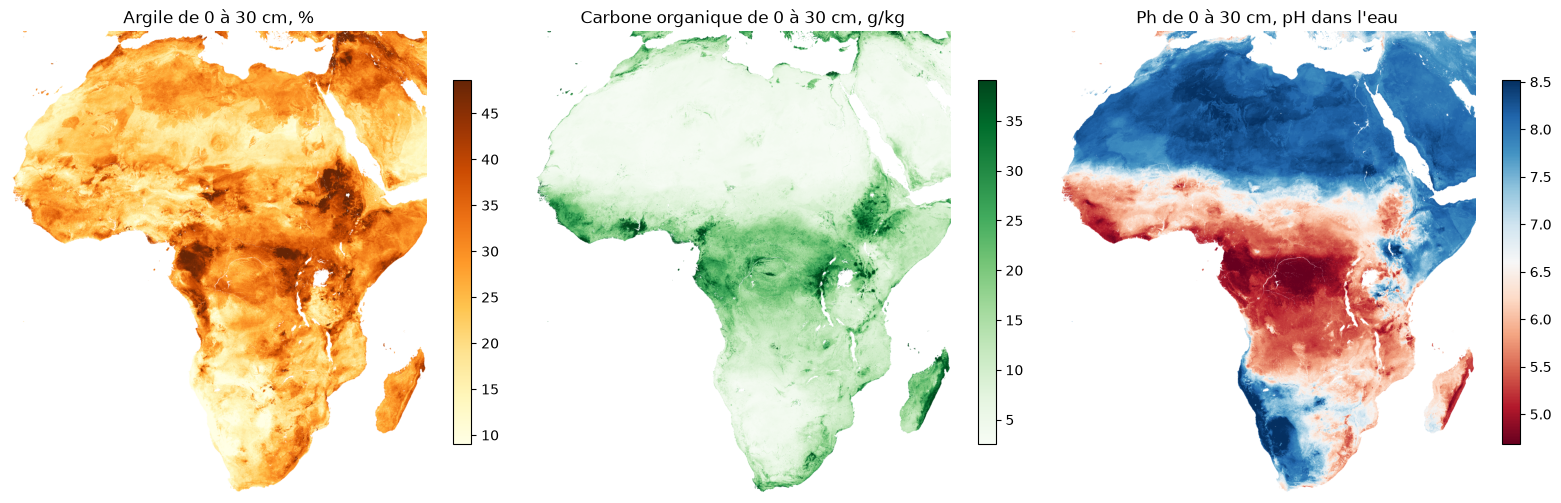

In [7]:
figure, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for axe, (propriete, carte) in zip(axes, [("clay", "YlOrBr"), ("soc", "Greens"), ("phh2o", "RdBu")]):
    couche = couche_0_30(propriete)[::4, ::4]
    image = axe.imshow(couche, cmap=carte, vmin=np.nanpercentile(couche, 1), vmax=np.nanpercentile(couche, 99))
    nom, _, unite = PROPRIETES[propriete]
    axe.set_title(f"{nom.replace('_', ' ').capitalize()} de 0 à 30 cm, {unite}")
    axe.set_axis_off()
    figure.colorbar(image, ax=axe, shrink=0.7)
plt.tight_layout()
plt.show()

**Constat**

- 56,2 % des pixels de la fenêtre ont une valeur, identiquement pour toutes les couches. Les autres couvrent la mer, les grands lacs, les villes et les surfaces sans sol que SoilGrids exclut.
- Aucune valeur n'est nulle, sauf pour les éléments grossiers, nuls dans 105 à 268 pixels selon la profondeur, ce qui reste plausible pour des sols alluviaux.
- Les valeurs restent dans des domaines physiques plausibles. Le pH va de 3,8 à 10,4, la densité apparente de 0,46 à 1,87 g/cm³, et le carbone organique médian décroît avec la profondeur, de 10,8 g/kg de 0 à 5 cm à 6,1 g/kg de 15 à 30 cm.
- La somme des trois fractions de la texture reste comprise entre 99,9 et 100,1 %.
- Les cartes retrouvent les grands traits des sols africains. Les sols du bassin du Congo et de la côte guinéenne sont acides, ceux du Sahara, du Sahel septentrional et du Kalahari alcalins, et le carbone organique se concentre sur les hauts plateaux éthiopiens, dans le bassin du Congo et sur la côte orientale de Madagascar.

**Analyse**

Les couches sont cohérentes entre elles et avec la géographie connue des sols. La fermeture de la texture rend le limon redondant avec l'argile et le sable, puisque sa part se déduit des deux autres.

### 6. Variables par lieu

La valeur d'un lieu est la moyenne de ses pixels valides. La projection de SoilGrids conserve les surfaces, et tous les pixels représentent donc 1 km². Un pixel appartient à un lieu lorsque son centre tombe dans le contour, et un lieu trop petit pour contenir un centre reçoit les pixels qu'il touche. La part de pixels valides est calculée sur l'argile.

In [8]:
sols_regional = pd.read_csv(DOSSIER_TRAITE / "sols_regional.csv.gz")
sols_survey = pd.read_csv(DOSSIER_TRAITE / "sols_survey.csv.gz")
variables = [f"{nom}_0_30" for nom, _, _ in PROPRIETES.values()]
print("regional :", sols_regional.shape, "| survey :", sols_survey.shape)
print("Zones de regional sans aucune valeur :", sols_regional.loc[sols_regional["argile_0_30"].isna(), "GDAM_ID"].tolist())
lieux_survey = sols_survey.drop_duplicates("lieu").dropna(subset=["lieu"])
print("Lieux de survey :", lieux_survey["nature_lieu"].value_counts().to_dict(),
      "| sans aucune valeur :", int(lieux_survey["argile_0_30"].isna().sum()))
display(pd.DataFrame({
    "pixels regional": sols_regional["pixels_sol"].describe(),
    "pixels grappes": lieux_survey.loc[lieux_survey["nature_lieu"] == "grappe", "pixels_sol"].describe(),
    "part valide regional": sols_regional["part_sol_valide"].describe(),
    "part valide grappes": lieux_survey.loc[lieux_survey["nature_lieu"] == "grappe", "part_sol_valide"].describe(),
}).round(3))
couverture = pd.DataFrame({
    "regional, lignes": pd.read_csv(DOSSIER_TRAITE / "regional_modelisation.csv.gz", usecols=["GDAM_ID"])["GDAM_ID"]
        .map(sols_regional.set_index("GDAM_ID")["argile_0_30"]).notna().mean(),
    "survey, lignes": sols_survey["argile_0_30"].notna().mean(),
}, index=["part avec variables de sol"])
display(couverture.round(4))
faibles = sols_regional[sols_regional["part_sol_valide"] < 0.5].sort_values("part_sol_valide")
print("Zones de regional dont moins de la moitié des pixels a une valeur :", len(faibles))
display(faibles[["GDAM_ID", "pixels_sol", "part_sol_valide"]].head(15))

regional : (1682, 12) | survey : (151138, 14)
Zones de regional sans aucune valeur : ['L2GHA15315', 'L2GHA15334', 'L2GHA15338', 'L2SEN37013']
Lieux de survey : {'grappe': 8045, 'zone': 375} | sans aucune valeur : 3


,pixels regional,pixels grappes,part valide regional,part valide grappes
count,1682.000,8045.000,1682.000,8045.000
mean,18626.426,78.958,0.958,0.955
std,44902.688,1.383,0.110,0.126
min,5.000,74.000,0.000,0.000
25%,1578.000,78.000,0.973,0.987
50%,5015.500,79.000,0.994,1.000
75%,15318.500,80.000,0.999,1.000
max,626808.000,82.000,1.000,1.000


,"regional, lignes","survey, lignes"
part avec variables de sol,0.9995,0.9928


Zones de regional dont moins de la moitié des pixels a une valeur : 22


,GDAM_ID,pixels_sol,part_sol_valide
994,L2GHA15334,30,0.000000
986,L2GHA15315,5,0.000000
1390,L2SEN37013,86,0.000000
996,L2GHA15338,42,0.000000
590,L1UGA3329,28593,0.018886
690,L2BEN02188,76,0.039474
990,L2GHA15319,20,0.100000
575,L1UGA3313,181,0.116022
1391,L2SEN37015,83,0.168675
989,L2GHA15318,83,0.228916


**Constat**

- Les 1 682 zones de `regional` comptent de 5 à 626 808 pixels, 5 016 en médiane. Les 8 045 voisinages de grappes en comptent de 74 à 82, pour une surface théorique de 78,5 km².
- 99,95 % des lignes de `regional` et 99,28 % des lignes de `survey` reçoivent des variables de sol.
- Quatre zones de `regional`, qui portent 68 lignes, n'ont aucun pixel valide. Ce sont Accra, Ledzokuku et Tema au Ghana, et Dakar au Sénégal, toutes urbaines. À Ashaiman, également au Ghana, les deux seuls pixels valides pour la texture sont masqués pour le carbone organique, le pH, la capacité d'échange et la densité apparente, dont les masques diffèrent légèrement en bordure des villes.
- 22 zones ont moins de la moitié de leurs pixels valides. Il s'agit surtout de villes, comme Cotonou à 3,9 % et Kampala à 11,6 %, et de zones recouvrant un lac. L'unité ougandaise nommée Lake Victoria ne garde que 1,9 % de ses 28 593 pixels, vraisemblablement ceux de ses îles, et le district de Nkhata Bay au Malawi 37,8 %, le reste couvrant le lac Malawi.
- Dans `survey`, les 1 088 lignes sans variable de sol comprennent les 1 085 lignes sans lieu et trois grappes de Dar es Salaam, en Tanzanie, entièrement urbaines.

**Analyse**

- Le masque urbain de SoilGrids correspond à la réalité du terrain, puisqu'une ville n'a pas de sol cultivé cartographiable. Les rendements déclarés pour les districts urbains d'Accra et de Dakar portent vraisemblablement sur des surfaces agricoles résiduelles ou périurbaines que la carte ne représente pas.
- Pour les zones lacustres, la moyenne des pixels valides décrit correctement les terres émergées, qui seules portent les cultures.

**Décisions**

- Les variables manquantes restent manquantes. Aucune imputation n'est faite à ce stade, le traitement des valeurs manquantes relevant de la modélisation.
- `pixels_sol` et `part_sol_valide` accompagnent chaque lieu, ce qui permet d'écarter ou de signaler les lieux dont la valeur repose sur peu de pixels.

### 7. Cohérence agronomique

Les corrélations de rang entre variables de sol des zones de `regional` sont comparées aux relations connues. Le pH, le carbone organique, la part de sable et la capacité d'échange sont ensuite rapprochés de la pluie de saison médiane de chaque zone, issue de `climat_regional.csv.gz`, la pluie étant une source indépendante de SoilGrids dans sa construction.

In [9]:
display(sols_regional[variables].describe().T.round(2))
display(sols_regional[variables].rank().corr().round(2))

climat = pd.read_csv(DOSSIER_TRAITE / "climat_regional.csv.gz", usecols=["GDAM_ID", "pluie_cumul", "bilan_hydrique"])
climat = climat.groupby("GDAM_ID")[["pluie_cumul", "bilan_hydrique"]].median()
jointure = sols_regional.set_index("GDAM_ID").join(climat, how="inner").dropna(subset=["ph_0_30", "pluie_cumul"])
print("Zones jointes :", len(jointure))
display(jointure[["ph_0_30", "carbone_organique_0_30", "sable_0_30", "cec_0_30"]].rank()
        .corrwith(jointure["pluie_cumul"].rank()).round(2).to_frame("correlation de rang avec la pluie de saison"))

,count,mean,std,min,25%,50%,75%,max
argile_0_30,1678.0,27.95,6.96,9.84,23.10,26.71,32.94,56.89
limon_0_30,1678.0,23.01,6.93,5.24,18.05,23.05,28.24,43.34
sable_0_30,1678.0,49.04,11.84,10.57,39.96,49.09,57.25,84.00
carbone_organique_0_30,1677.0,18.18,12.11,2.94,9.88,14.71,23.88,90.09
azote_0_30,1678.0,1.57,1.24,0.34,0.87,1.17,1.88,11.07
ph_0_30,1677.0,6.21,0.79,4.59,5.68,6.08,6.48,8.46
cec_0_30,1677.0,16.04,7.72,4.73,10.12,13.78,20.14,50.10
densite_apparente_0_30,1677.0,1.39,0.12,0.94,1.31,1.41,1.47,1.67
elements_grossiers_0_30,1678.0,11.86,5.99,1.30,7.10,11.76,15.47,37.75


,argile_0_30,limon_0_30,sable_0_30,carbone_organique_0_30,azote_0_30,ph_0_30,cec_0_30,densite_apparente_0_30,elements_grossiers_0_30
argile_0_30,1.00,0.47,-0.85,0.54,0.57,-0.14,0.55,-0.48,0.10
limon_0_30,0.47,1.00,-0.85,0.31,0.36,0.18,0.56,0.02,0.49
sable_0_30,-0.85,-0.85,1.00,-0.49,-0.54,-0.02,-0.64,0.27,-0.33
carbone_organique_0_30,0.54,0.31,-0.49,1.00,0.94,-0.54,0.57,-0.63,0.21
azote_0_30,0.57,0.36,-0.54,0.94,1.00,-0.48,0.63,-0.61,0.30
ph_0_30,-0.14,0.18,-0.02,-0.54,-0.48,1.00,0.20,0.54,0.10
cec_0_30,0.55,0.56,-0.64,0.57,0.63,0.20,1.00,-0.21,0.43
densite_apparente_0_30,-0.48,0.02,0.27,-0.63,-0.61,0.54,-0.21,1.00,0.07
elements_grossiers_0_30,0.10,0.49,-0.33,0.21,0.30,0.10,0.43,0.07,1.00


Zones jointes : 1287


,correlation de rang avec la pluie de saison
ph_0_30,-0.61
carbone_organique_0_30,0.22
sable_0_30,0.07
cec_0_30,-0.32


**Constat**

- Le carbone organique et l'azote ont une corrélation de rang de 0,94. Le sable est corrélé négativement à l'argile et au limon, à -0,85 chacun, et la densité apparente au carbone organique, à -0,63.
- Sur les 1 287 zones dotées d'une pluie de saison, le pH décroît nettement avec la pluie, avec une corrélation de rang de -0,61. La capacité d'échange décroît aussi, à -0,32, et le carbone organique croît légèrement, à 0,22.

**Analyse**

- Les relations retrouvées sont celles qu'attend la science du sol. L'azote du sol est surtout organique, la matière organique allège le sol, et les pluies abondantes lessivent les bases et acidifient les sols.
- La corrélation entre carbone organique et azote traduit une forte redondance. SoilGrids prédit ces propriétés avec les mêmes covariables, climatiques notamment, ce qui explique aussi une part de leur lien avec la pluie.

**Conséquences pour la suite**

- Les variables de sol apportent une information en partie liée au climat. Leur contribution propre devra être mesurée lors de la modélisation, par exemple en comparant un modèle avec et sans elles.
- Le limon et l'azote sont redondants avec d'autres variables. Ils sont conservés dans les fichiers, et le choix de les garder relève de la modélisation.

### 8. Synthèse

**Résultats**

| Élément | Résultat |
|---|---|
| Couches acquises | 27, soit neuf propriétés à trois profondeurs, vérifiées par l'empreinte SHA-256 publiée |
| Volume conservé | 787 Mo de découpages, pour 4,68 Go de sources vérifiées puis supprimées |
| Version à 1 km | Identique au premier aperçu des mosaïques à 250 m, position incertaine à 1 km près |
| Écart à l'échelle de 5 km | Corrélation de 0,94 à 0,99 avec la moyenne exacte à 250 m |
| `sols_regional.csv.gz` | 1 682 zones, clé `GDAM_ID`, 4 zones urbaines sans valeur portant 68 lignes |
| `sols_survey.csv.gz` | 151 138 lignes, clé `id_ligne`, 99,28 % avec variables de sol |

**Limites**

- SoilGrids est une prédiction statistique, dont l'incertitude est élevée en Afrique. Ses valeurs décrivent un état moyen et ne varient pas d'une année à l'autre.
- La méthode de calcul de la version à 1 km n'est pas documentée par ISRIC. Les contrôles montrent qu'elle approche la moyenne des pixels fins sans l'égaler, avec un décalage de position de l'ordre de 1 km.
- Comme pour le climat, les moyennes sont pondérées par la surface seule. Le masque des terres cultivées prévu à la section 5.1 de `docs/explanatory_variables.md` n'est pas appliqué, et une zone mêlant cultures, forêts et parcours reçoit la moyenne de l'ensemble.
- Les fichiers ne contiennent aucune variable pour `cropcut`, dont les variables explicatives restent à construire pour la validation externe.